In [1]:

import pandas as pd

df = pd.read_csv("/content/titanic (1).csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [2]:

df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:

df.isnull().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [5]:

survival_counts = df["Survived"].value_counts().sort_index()

print("Passenger survival counts:")
print(survival_counts)

print("\nSurvival percentages:")
print(
    (df["Survived"].value_counts(normalize=True).sort_index() * 100).round(2)
)


Passenger survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


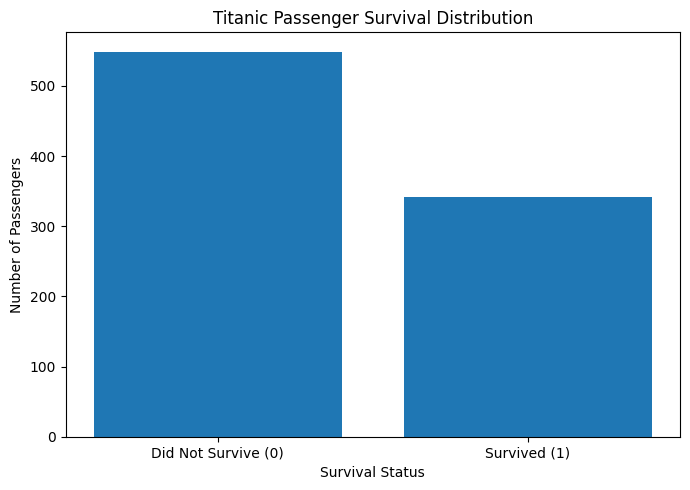

In [6]:

import matplotlib.pyplot as plt

survival_counts = df["Survived"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Did Not Survive (0)", "Survived (1)"],
    survival_counts.values
)

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

survival_by_sex = pd.crosstab(
    df["Sex"],
    df["Survived"]
)

print(survival_by_sex)


Survived    0    1
Sex               
female     81  233
male      468  109


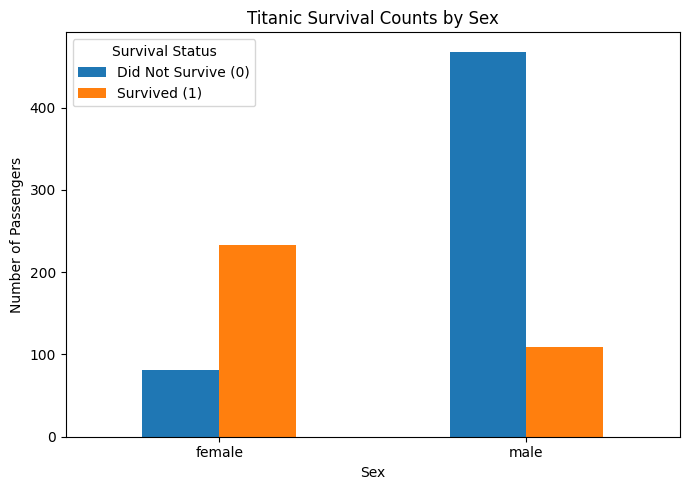

In [8]:

survival_by_sex = pd.crosstab(df["Sex"], df["Survived"])

survival_by_sex.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Titanic Survival Counts by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(
    ["Did Not Survive (0)", "Survived (1)"],
    title="Survival Status"
)
plt.tight_layout()
plt.show()


In [9]:

survival_by_class = pd.crosstab(
    df["Pclass"],
    df["Survived"]
)

print(survival_by_class)


Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


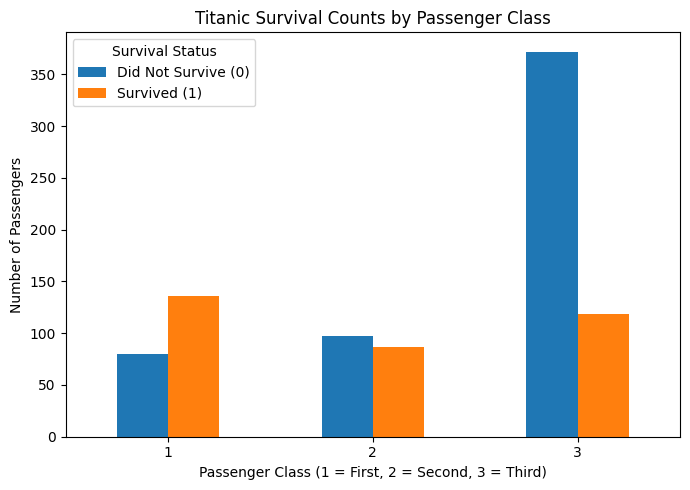

In [10]:

survival_by_class.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Titanic Survival Counts by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(
    ["Did Not Survive (0)", "Survived (1)"],
    title="Survival Status"
)
plt.tight_layout()
plt.show()


In [11]:

print(
    df.groupby("Survived")["Age"].describe().round(2)
)


          count   mean    std   min   25%   50%   75%   max
Survived                                                   
0         424.0  30.63  14.17  1.00  21.0  28.0  39.0  74.0
1         290.0  28.34  14.95  0.42  19.0  28.0  36.0  80.0


<Figure size 700x500 with 0 Axes>

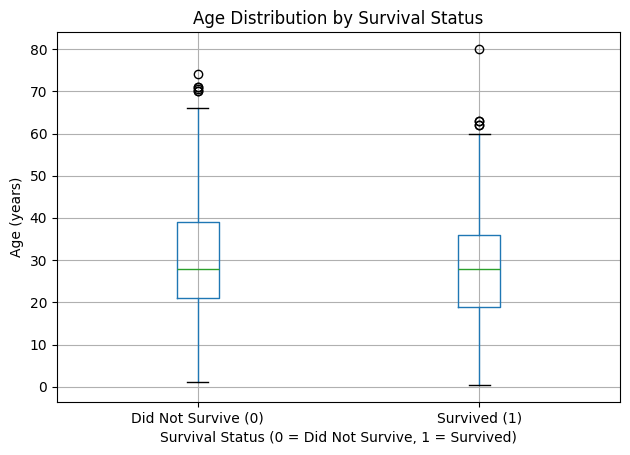

In [12]:

plt.figure(figsize=(7, 5))

df.boxplot(
    column="Age",
    by="Survived"
)

plt.title("Age Distribution by Survival Status")
plt.suptitle("")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Age (years)")
plt.xticks([1, 2], ["Did Not Survive (0)", "Survived (1)"])
plt.tight_layout()
plt.show()


In [13]:

numeric_columns = [
    "Survived",
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

correlation = df[numeric_columns].corr()

print(correlation.round(2))


          Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
Age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp        -0.04    0.08 -0.31   1.00   0.41  0.16
Parch         0.08    0.02 -0.19   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00


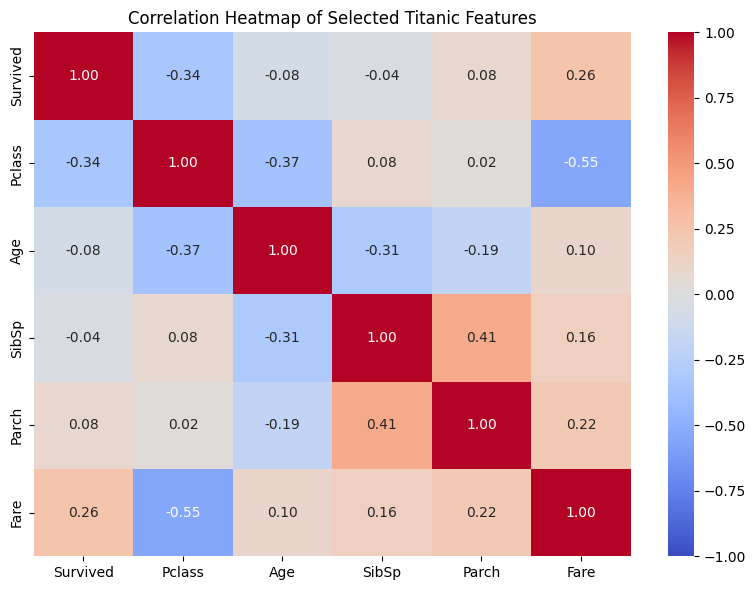

In [14]:

import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Selected Titanic Features")
plt.tight_layout()
plt.show()


In [15]:
# Select the features used for prediction
features = ["Pclass", "Sex", "Age", "SibSp",
            "Parch", "Fare", "Embarked"]

X = df[features]
y = df["Survived"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target values:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_preprocessing = SimpleImputer(strategy="median")

categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessing, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Preprocessing and Logistic Regression model created.")

Preprocessing and Logistic Regression model created.


In [18]:
# Train the Logistic Regression model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [19]:
# Predict survival for the test data
y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Survival": y_test,
    "Predicted Survival": y_pred
})

print(results.head(10))

     Actual Survival  Predicted Survival
565                0                   0
160                0                   0
553                1                   0
860                0                   0
241                1                   1
559                1                   0
387                1                   1
536                0                   0
698                0                   0
99                 0                   0


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1-score: 0.7244

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



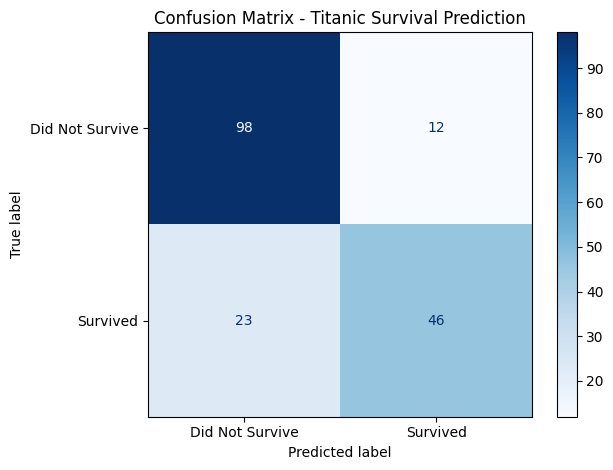

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Titanic Survival Prediction")
plt.tight_layout()
plt.show()

ROC-AUC Score: 0.8437


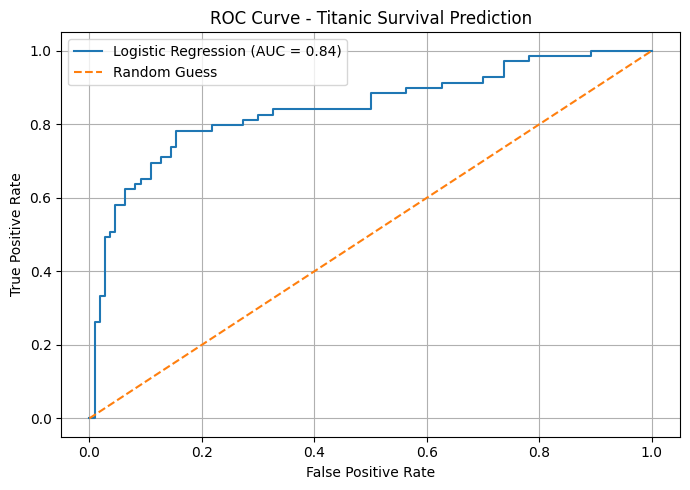

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probability that each passenger survived
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC score
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(auc_score, 4))

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.title("ROC Curve - Titanic Survival Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
# Get the names of the features after preprocessing
feature_names = model.named_steps["preprocessing"].get_feature_names_out()

# Get the Logistic Regression coefficients
coefficients = model.named_steps["classifier"].coef_[0]

# Display features and their coefficients
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_table["Coefficient"] = coefficient_table["Coefficient"].round(4)

print(coefficient_table.sort_values(
    by="Coefficient",
    ascending=False
).to_string(index=False))

                Feature  Coefficient
categorical__Sex_female       1.3073
categorical__Embarked_Q       0.3086
categorical__Embarked_C       0.0370
          numeric__Fare       0.0022
           numeric__Age      -0.0389
         numeric__Parch      -0.0804
         numeric__SibSp      -0.2479
categorical__Embarked_S      -0.3495
        numeric__Pclass      -1.1000
  categorical__Sex_male      -1.3113


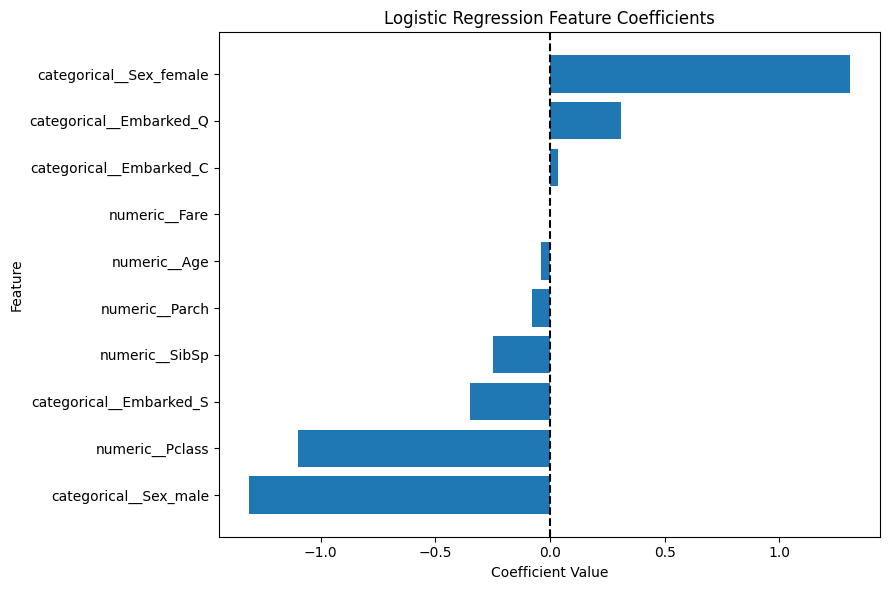

In [25]:
# Sort coefficients for a clearer graph
coef_plot = coefficient_table.sort_values(by="Coefficient")
plt.figure(figsize=(9, 6))
plt.barh(
    coef_plot["Feature"],
    coef_plot["Coefficient"]
)
plt.axvline(0, linestyle="--", color="black")
plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [26]:
import joblib

joblib.dump(model, "titanic_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [27]:
from google.colab import files

files.download("titanic_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import sklearn
print(sklearn.__version__)

1.6.1
